In [65]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

In [66]:
def plot_graph(g,title="",highlight_edges=[]):
    pos=nx.get_node_attributes(g,"pos")
    plt.title(title)

    nx.draw(g,pos=pos,labels={x:x for x in g.nodes})
    weights=nx.get_edge_attributes(g,"weight")
    nx.draw_networkx_edge_labels(g,pos,edge_labels=weights)
    nx.draw_networkx_edges(g,pos,edgelist=highlight_edges,edge_color="r")
    nx.draw_networkx_edge_labels(g,
                                 pos,                                   
                                 edge_labels={
                                        e:w
                                        for e,w in weights.items()
                                        if e in map(lambda x:tuple(sorted(x)),highlight_edges)
                                    },
                                 font_color="r",
                                )
    plt.show()

In [67]:
def zero_divide(a,b):
     return np.divide(a,b,out=np.zeros_like(a),where=b!=0)

In [68]:
class ACOTSP:
    def __init__(self,g,n_ants=100,alpha=1,beta=5,q=100,rho=.6):
        self.g=g
        self.n_nodes=len(g.nodes)
        distance=nx.to_numpy_array(g)
        self.visibility=zero_divide(np.ones_like(distance),distance)
        self.n_ants=n_ants
        self.alpha=alpha
        self.beta=beta
        self.q=q
        self.rho=rho
        self.phe_trail=np.ones((self.n_nodes,self.n_nodes))

    def compute_prob(self,visited):
        self.prob=self.phe_trail**self.alpha*self.visibility**self.beta
        self.prob[:,np.array(list(visited))]=0
        prob_sum=self.prob.sum(-1,keepdims=True)
        self.prob=zero_divide(self.prob,prob_sum)

        return self.prob

    def initialize(self):
        nodes=list(self.g.nodes)
        self.ant_pos=np.random.choice(nodes,self.n_ants)

    def path_length(self,path):
        edge_weights=nx.get_edge_attributes(self.g,"weight")
        return sum((edge_weights[tuple(sorted(i))] for i in path))

    def ant_tour(self,k):
        current=self.ant_pos[k]
        visited={current}
        path=[]
        self.compute_prob(visited)

        while True:
            prev=current
            current=np.random.choice(self.n_nodes,p=self.prob[current])
            visited.add(current)
            path.append((prev,current))

            if np.all(self.prob[current]==0):
                break
            self.compute_prob(visited)

        self.paths[k]=path

    def update_pheromone_train(self):
        d_phe_trail=np.zeros((self.n_nodes,self.n_nodes,self.n_ants))

        for k in range(self.n_ants):
            if len(self.paths[k])==self.n_nodes-1:
                for i,j in self.paths[k]:
                    d_phe_trail[i,j,k]=d_phe_trail[j,i,k]=self.q/self.path_lengths[k]

        d_phe_trail=d_phe_trail.sum(-1)
        self.phe_trail=self.rho*self.phe_trail+d_phe_trail

    def run(self,n_iter=1):
        self.initialize()
        for t in range(n_iter):
            self.paths=[0 for _ in range(self.n_ants)]
            for k in range(self.n_ants):
                self.ant_tour(k)
            self.path_lengths=list(map(self.path_length,self.paths))
            self.update_pheromone_train()
            self.hamiltonian_paths=[path for path in self.paths if len(path)==self.n_nodes-1]
            self.hamiltonian_path_lengths=list(map(self.path_length,self.hamiltonian_paths))

        print("shortest hamillonian path lenght:",self.min_path_lenght)

    @property
    def min_path_lenght(self):
        try:
            return min(self.hamiltonian_path_lengths)
        except:
            return None

    @property
    def min_path(self):
        try:
            return self.hamiltonian_paths[np.argmin(self.hamiltonian_path_lengths)]
        except:
            return None

            

In [69]:
"""def generate_random_weighted_graph(n_nodes,edge_propability,min_weight,max_weight,seed=0):
    
    np.random.seed(0)
    g=nx.Graph()
    g.add_nodes_from(range(10))
    pos = {i: (np.random.random(), np.random.random()) for i in range(10)}
 
    nx.set_node_attributes(g,pos,"pos")

    for i,j in combinations(range(10),2):
        if np.random.random()<0.5:
            weight=np.random.randint(1,21)
            g.add_edge(i,j,weight=weight)
    return g
"""
def generate_random_weighted_graph(n, low, high):
    g = nx.generators.complete_graph(n)
    g.add_weighted_edges_from([(a, b, np.random.randint(1,20)) for a, b in g.edges()])
    nx.set_node_attributes(g, nx.spring_layout(g), "pos")
    return g

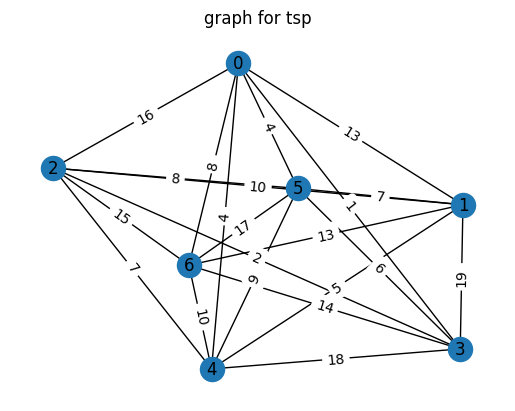

In [70]:
np.random.seed(0)
g=generate_random_weighted_graph(7,1,20)
#g=generate_random_weighted_graph(10,50,1,20,seed=10)
plot_graph(g,"graph for tsp")

In [71]:
acotsp=ACOTSP(g,n_ants=10,alpha=3,beta=5,q=10,rho=.1)
acotsp.run(n_iter=50)

shortest hamillonian path lenght: 29


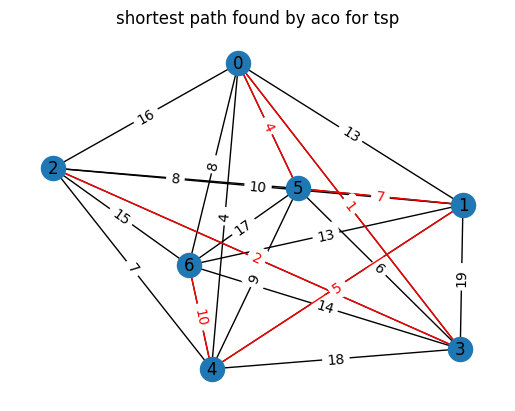

In [72]:
plot_graph(g,"shortest path found by aco for tsp",acotsp.min_path)